In [80]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras
import numpy as np
import matplotlib.pyplot as plt
import keras_hub


## Business Understanding
E E EE E E 

## Data Understanding

The data consists of 3 classes: cups, bottles and plates. All of the pictures are taken in a 224x224 format and are taken by the team members themselves. Different types of cups, bottles and plates are used for variation and backgrounds. 

# Data Preparation

The data is already in the desired format (224x224) and all in jpg. So the only steps needed to take is to import the pictures into the notebook, seperate the test- from the trainset and give the pictures labels.

In [81]:
# import pictures
from pathlib import Path

DATA_DIR = Path("images_224")
IMG_SIZE = (224, 224)
class_names = sorted(p.name for p in (DATA_DIR / "train").iterdir() if p.is_dir())

def load_split(split):
    images, labels = [], []
    for label, cls in enumerate(class_names):
        for f in sorted((DATA_DIR / split / cls).glob("*.jpg")):
            img = keras.utils.load_img(f, target_size=IMG_SIZE)
            images.append(keras.utils.img_to_array(img))
            labels.append(label)
    return np.array(images, dtype="float32"), np.array(labels)

x_train, y_train = load_split("train")
x_val, y_val = load_split("val")
x_test, y_test = load_split("test")

print("Classes:", class_names)
print("Train:", x_train.shape, np.bincount(y_train))
print("Val:  ", x_val.shape, np.bincount(y_val))
print("Test: ", x_test.shape, np.bincount(y_test))

Classes: ['bottles', 'cups', 'plates']
Train: (270, 224, 224, 3) [ 99 101  70]
Val:   (62, 224, 224, 3) [23 23 16]
Test:  (82, 224, 224, 3) [30 31 21]


## Modeling

We will be trying three different ways to train a CNN model. First we will try to model our own model. The second model will be a pretrained model where we use only feature extraction. The third and last one will be a finetuned pretrained model. 

### Own Model 

After reviewing different CNN architechtures; we decided to take insnipiration from the AlexNet CNN architechture. AlexNet contains eight layers: the first five are convolutional layers, some of them followed by max-pooling layers, and the last three are fully connected layers.



In [82]:
#(CONV → RN → MP)2 → (CONV3 → MP) → (FC → DO)2 → Linear → softmax
from keras import layers

model = keras.Sequential([
    keras.Input(shape=(*IMG_SIZE, 3)),
    layers.Rescaling(1 / 255),

    #DATA AUGMENTATION
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.1),

    # (CONV → RN → MP) x 2
    layers.Conv2D(96, 11, strides=4, activation="relu"),
    layers.BatchNormalization(),                    # RN
    layers.MaxPooling2D(pool_size=3, strides=2),

    layers.Conv2D(256, 5, padding="same", activation="relu"),
    layers.BatchNormalization(),                    # RN
    layers.MaxPooling2D(pool_size=3, strides=2),

    # CONV x 3 → MP
    layers.Conv2D(384, 3, padding="same", activation="relu"),
    layers.Conv2D(384, 3, padding="same", activation="relu"),
    layers.Conv2D(256, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=3, strides=2),

    # (FC → DO) x 2
    layers.Flatten(),
    layers.Dense(4096, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(4096, activation="relu"),
    layers.Dropout(0.5),


    layers.Dense(len(class_names), activation="softmax"),
], name="alexnet")

model.summary()

Model: "alexnet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_10 (Rescaling)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_10 (RandomFlip)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_6               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_6 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_10           │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_6               │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_73 (Conv2D)              │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_58          │ (None, 54, 54, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_49 (MaxPooling2D) │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_74 (Conv2D)              │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_59          │ (None, 26, 26, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_50 (MaxPooling2D) │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_75 (Conv2D)              │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_76 (Conv2D)              │ (None, 12, 12, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_77 (Conv2D)              │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_51 (MaxPooling2D) │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 4096)           │    26,218,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_26 (Dropout)            │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 3)              │        12,291 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 46,760,707 (178.38 MB)

 Trainable params: 46,760,003 (178.38 MB)

 Non-trainable params: 704 (2.75 KB)

Now we train the model and evaluate it with our limited amount of data.

In [83]:
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    metrics=["accuracy"]
)

history_own = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    batch_size=8,
    epochs=50,
)

Epoch 1/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 11s 164ms/step - accuracy: 0.3667 - loss: 1.3769 - val_accuracy: 0.5161 - val_loss: 1.0960
Epoch 2/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 5s 142ms/step - accuracy: 0.5074 - loss: 0.9938 - val_accuracy: 0.3710 - val_loss: 1.0940
Epoch 3/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 5s 141ms/step - accuracy: 0.6185 - loss: 0.8577 - val_accuracy: 0.3710 - val_loss: 1.0970
Epoch 4/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 5s 140ms/step - accuracy: 0.6593 - loss: 0.8011 - val_accuracy: 0.3710 - val_loss: 1.0915
Epoch 5/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 5s 136ms/step - accuracy: 0.7185 - loss: 0.6435 - val_accuracy: 0.3710 - val_loss: 1.1129
Epoch 6/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 5s 136ms/step - accuracy: 0.7148 - loss: 0.6876 - val_accuracy: 0.3871 - val_loss: 1.1245
Epoch 7/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 5s 134ms/step - accuracy: 0.7370 - loss: 0.6084 - val_accuracy: 0.4194 - val_loss: 1.1598
Epoch 8/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 5s 136ms/step - accuracy: 0.7556 - loss: 0.6111 - val_accuracy: 0

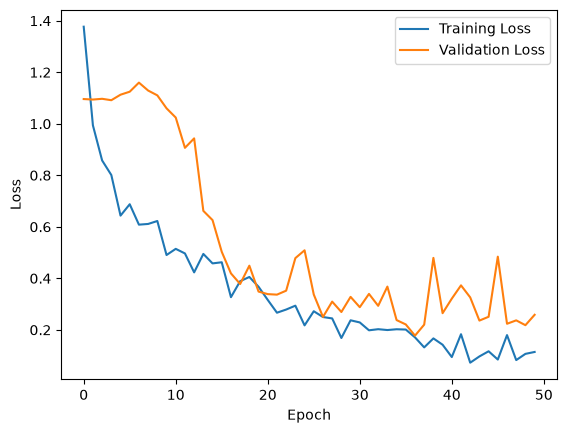

In [84]:
# plot training and validation

plt.plot(history_own.history['loss'], label='Training Loss')
plt.plot(history_own.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [85]:
test_loss, test_acc = model.evaluate(x_test, y_test, batch_size=32)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 177ms/step - accuracy: 0.9390 - loss: 0.1676
Test loss: 0.1676
Test accuracy: 0.9390


In [86]:
conv_base = keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3))
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_17 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 412ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 479ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 366ms/step
(270, 7, 7, 512)
Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step - accuracy: 0.7852 - loss: 3.0561 - val_accuracy: 0.9194 - val_loss: 0.8670
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.8778 - loss: 1.8868 - val_accuracy: 0.9355 - val_loss: 0.7844
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9148 - loss: 1.2947 - val_accuracy: 0.9516 - val_loss: 0.6693
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8815 - loss: 1.8162 - val_accuracy: 0.9194 - val_loss: 1.2006
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9111 - loss: 1.3374 - val_accuracy: 0.9516 - val_loss: 0.7799
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9333 - loss: 0.9923 - val_accuracy: 0.9677 - val_loss: 0.5199
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9519 - loss: 0.7438 - val_accuracy: 0.9677 - val_los

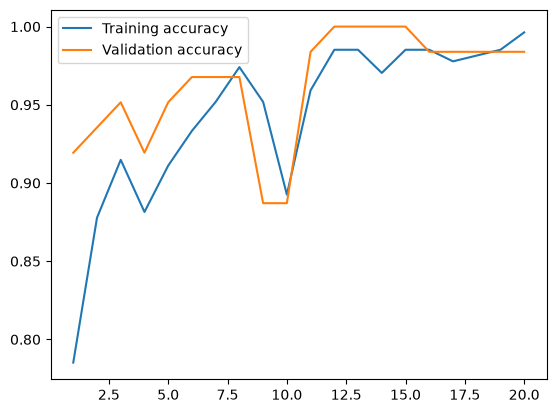

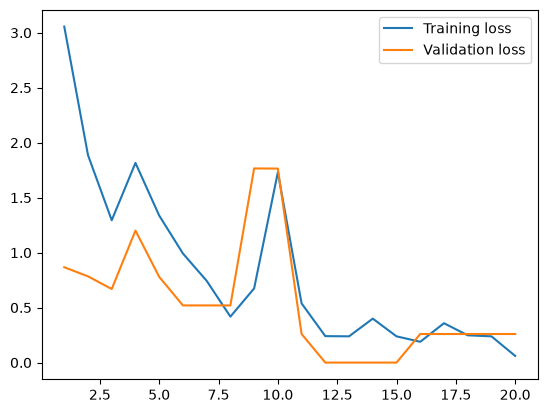

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9390 - loss: 0.8415   
Test accuracy: 0.939


In [87]:
def get_features_and_labels(images, labels):
    # copy: preprocess_input modifies float arrays in place
    preprocessed_images = keras.applications.vgg16.preprocess_input(images.copy())
    features = conv_base.predict(preprocessed_images, batch_size=32)
    return features, labels

train_features, train_labels = get_features_and_labels(x_train, y_train)
val_features, val_labels = get_features_and_labels(x_val, y_val)
test_features, test_labels = get_features_and_labels(x_test, y_test)

print(train_features.shape)
inputs = keras.Input(shape=train_features.shape[1:])
x = layers.Flatten()(inputs)
x = layers.Dense(256)(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.compile(loss="sparse_categorical_crossentropy",
              optimizer="rmsprop",
              metrics=["accuracy"])

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="feature_extraction.keras",
        save_best_only=True,
        monitor="val_loss")
]

history = model.fit(
    train_features, train_labels,
    epochs=20,
    validation_data=(val_features, val_labels),
    callbacks=callbacks)
accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = list(range(1, len(accuracy)+1))
plt.plot(epochs, accuracy, label="Training accuracy")
plt.plot(epochs, val_accuracy, label="Validation accuracy")
plt.legend()
plt.figure()
plt.plot(epochs, loss, label="Training loss")
plt.plot(epochs, val_loss, label="Validation loss")
plt.legend()
plt.show()
test_model = keras.models.load_model("feature_extraction.keras")
test_loss, test_acc = test_model.evaluate(test_features, test_labels)
print(f"Test accuracy: {test_acc:.3f}")